## Goals

In this lab, you will practice quantizing a classical neural network model. The goals of this assignment are as follows:

- Understand the basic concept of **quantization**
- Implement and apply **linear quantization**, the very basic **Post-Training Quantization (PTQ)**
- Implement and apply **Quantization-Aware Training (QAT)** for linear quantization

**!!! Before you start, you need to upload the two following files to your colab project directory (/content/)!!!**
- vgg_cifar.py
- cifar10_vgg13_acc_94.730.pt

## Setup

In [1]:
from __future__ import print_function
import os
import sys
import logging
import argparse
import time
from time import strftime
import torch
import torch.optim as optim
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import Function
from torch.nn.parameter import Parameter
from torchvision import datasets, transforms
import yaml
from functools import partial

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from vgg_cifar import vgg13

# settings
parser = argparse.ArgumentParser(description='PyTorch CIFAR10 admm training')
parser.add_argument('--epochs', type=int, default=160, metavar='N',
                    help='number of epochs to train (default: 160)')
parser.add_argument('--batch-size', type=int, default=64, metavar='N',
                    help='training batch size (default: 64)')
parser.add_argument('--seed', type=int, default=1, metavar='S',
                    help='random seed (default: 1)')
parser.add_argument('--load-model-path', type=str, default="content/cifar10_vgg13_acc_94.730.pt",
                    help='Path to pretrained model')


# --- for dubeg use ---------
# args_list = [
#     "--epochs", "160",
#     "--seed", "123",
#     # ... add other arguments and their values ...
# ]
# args = parser.parse_args(args_list)
args = parser.parse_args([])

def get_dataloaders(args):
    train_loader = torch.utils.data.DataLoader(
        datasets.CIFAR10('./data.cifar10', train=True, download=True,
                         transform=transforms.Compose([
                             transforms.Pad(4),
                             transforms.RandomCrop(32),
                             transforms.RandomHorizontalFlip(),
                             transforms.ToTensor(),
                             transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
                         ])),
        batch_size=args.batch_size, shuffle=True)

    test_loader = torch.utils.data.DataLoader(
        datasets.CIFAR10('./data.cifar10', train=False, download=True,
                         transform=transforms.Compose([
                            transforms.ToTensor(),
                            transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
                        ])),
        batch_size=256, shuffle=False)

    return train_loader, test_loader

def test(model, use_cuda, test_loader):
    model.eval()
    loss_func = torch.nn.CrossEntropyLoss(reduction='sum')
    test_loss = 0
    correct = 0
    with torch.no_grad():
        for data, target in test_loader:
            if use_cuda:
                data, target = data.cuda(), target.cuda()
            output = model(data)
            test_loss += loss_func(output, target).item()  # sum up batch loss
            pred = output.max(1, keepdim=True)[1]  # get the index of the max log-probability
            correct += pred.eq(target.view_as(pred)).sum().item()

    test_loss /= len(test_loader.dataset)
    accuracy = 100. * float(correct) / float(len(test_loader.dataset))

    print('\nTest set: Average loss: {:.4f}, Accuracy: {}/{} ({:.4f}%)\n'.format(
        test_loss, correct, len(test_loader.dataset), accuracy))

    return accuracy

/home/myid/sb92570/anaconda3/envs/cvgl/lib/python3.10/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


##Implement Linear Quantization Function
This function should be able to quantize weights from a layer to the given number of bit representation.

### Step 1. Compute scaling factor and normalize weights to [-1, 1]
The scaling factor is defined as the maximum absolute value of the weights:
$$
s = |w|_{\max}
$$
Then normalize the weights:
$$
w_{\text{norm}} = \frac{w}{s}
$$

### Step 2. Map to integer domain
$$
q = \mathrm{round}\!\left( w_{\text{norm}} \times (2^{b-1} - 1) \right)
$$

where $q \in [-2^{b-1}, 2^{b-1}-1]$.

### Step 3. Re-scale using a scaling factor \(s\). This step is also called De-quantization.
$$
\hat{w} = s \times \frac{q}{2^{b-1} - 1}
$$

In [2]:
def linear_quantization(w, bit):
    """ quantize a layer of weights to a fixed bits representation """
    """ take weight tensor as input """
    """ example: weight.data = manually_quant(w=weight, bit=4) """
    if bit == 32:
        return w

    # Follow the instructions (3 steps) above.
    # ======= Your code starts from here===========
    # Step 1. Compute scaling factor and normalize weights to [-1, 1]
    s = torch.max(torch.abs(w))

    if s == 0:
        return w

    w_norm = torch.div(w, s)

    # Step 2. Map to integer domain
    q = torch.round(torch.mul(w_norm, 2**(bit-1)-1))

    # Step 3. Re-scale using a scaling factor (s). De-quantization.
    w = torch.mul(s, torch.div(q, 2**(bit-1)-1))
    # =============================================

    return w


def quantize_model(model, bit):
    """Based on the linear_quantization() function you have implemented, write this function for quantizing the entire model weights in CONV and FC layers."""
    # ======= Your code starts from here===========
    with torch.no_grad():
        for layer in model.modules():
            if isinstance(layer, (nn.Conv2d, nn.Linear)):
                layer.weight.copy_(linear_quantization(layer.weight, bit))
    # =============================================


    return model

## Check if your model has been successfully quantized.
You can use the following check_model_quantization() function to check your model.
You can implement your code in the main() function provided below.

In [3]:
def check_quantization(weight, display=True):
    if isinstance(weight, torch.nn.parameter.Parameter):
        np_weight = weight.detach().cpu().numpy()
    elif isinstance(weight, torch.Tensor):
        np_weight = weight.cpu().numpy()
    elif isinstance(weight, np.ndarray):
        np_weight = weight
    else:
        np_weight = weight

    unique, counts = np.unique(np_weight.flatten(), return_counts=True)
    un_list = np.asarray((unique, counts)).T

    scale = np.max(np.abs(np_weight))
    if display:
        print("Unique quant levels:", len(un_list))
        # print("max abs (scale) value is: {}".format(scale))

    return scale, len(un_list)

def check_model_quantization(model):
    for name, module in model.named_modules():
        if isinstance(module, (nn.Conv2d, nn.Linear)): # Fixed indentation here
            # Check if the module has a 'weight' attribute
            if hasattr(module, 'weight') and module.weight is not None:
                with torch.no_grad():
                    print("layer: ", name)
                    check_quantization(module.weight, display=True)

In [4]:
def main_PTQ(bit_width=4):
    # Modified by: Braveenan Sritharan
    # Date: October 28, 2026

    use_cuda = torch.cuda.is_available()

    # setup random seed
    np.random.seed(args.seed)
    torch.manual_seed(args.seed)
    if use_cuda:
        torch.cuda.manual_seed(args.seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    # set up model archetecture and load pretrained dense model

    model = vgg13()
    model.load_state_dict(torch.load(args.load_model_path))
    if use_cuda:
        model.cuda()

    _, test_loader = get_dataloaders(args)

    # check model quantizaiton status and test accuracy before quantization
    check_model_quantization(model)
    accuracy_bq = test(model, use_cuda, test_loader)

    quantize_model(model, bit_width)

    # check model quantizaiton status and test accuracy again after quantization
    check_model_quantization(model)
    accuracy_aq = test(model, use_cuda, test_loader)

    print("main finished!")

    return accuracy_bq, accuracy_aq

## Practice 1
Next, you need to test the model's testing accuracy at 32, 16, 8, 6, 4, and 3 bits, and plot the accuracy curve.
You can modify your main_PTQ() function for this purpose.


========== Running 32-bit Weight Quantization ==========


/tmp/ipykernel_3888983/4292181192.py:19: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(args.load_model_path))


Files already downloaded and verified
Files already downloaded and verified
layer:  features.0
Unique quant levels: 1728
layer:  features.3
Unique quant levels: 36853
layer:  features.7
Unique quant levels: 73701
layer:  features.10
Unique quant levels: 147291
layer:  features.14
Unique quant levels: 294346
layer:  features.17
Unique quant levels: 587377
layer:  features.21
Unique quant levels: 1170452
layer:  features.24
Unique quant levels: 2322861
layer:  features.28
Unique quant levels: 2326341
layer:  features.31
Unique quant levels: 2330411
layer:  classifier
Unique quant levels: 5120

Test set: Average loss: 0.3298, Accuracy: 9473/10000 (94.7300%)

layer:  features.0
Unique quant levels: 1728
layer:  features.3
Unique quant levels: 36853
layer:  features.7
Unique quant levels: 73701
layer:  features.10
Unique quant levels: 147291
layer:  features.14
Unique quant levels: 294346
layer:  features.17
Unique quant levels: 587377
layer:  features.21
Unique quant levels: 1170452
layer:

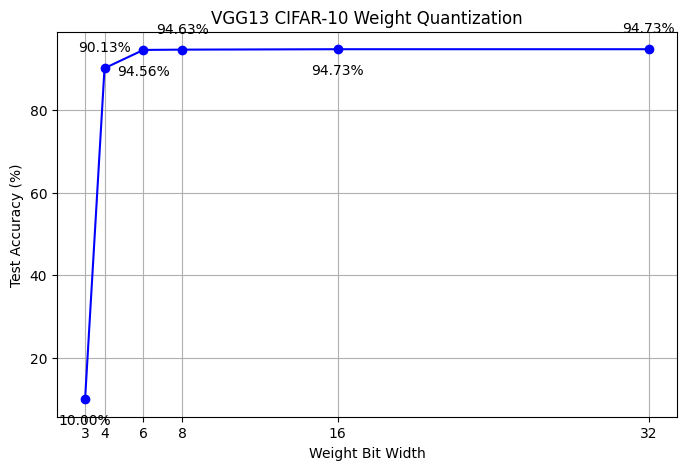

In [5]:
# Created by: Braveenan Sritharan
# Date: October 28, 2026
# Evaluate weight quantization at different bit widths and save accuracy results.

# ------- testing your functions -------------
bit_widths = [32, 16, 8, 6, 4, 3]
accuracies = []

for bit_width in bit_widths:
    print(f"\n========== Running {bit_width}-bit Weight Quantization ==========")

    accuracy_bq, accuracy_aq = main_PTQ(bit_width)

    accuracies.append(accuracy_aq)

    print(f"{bit_width}-bit Test Accuracy: {accuracy_aq:.4f}%")

os.makedirs("results", exist_ok=True)

plt.figure(figsize=(8, 5))
plt.plot(bit_widths, accuracies, marker='o', color='blue')

# Display accuracy above each point
for i, (bit_width, accuracy) in enumerate(zip(bit_widths, accuracies)):
    offset = 12 if i % 2 == 0 else -18

    plt.annotate(
        f"{accuracy:.2f}%",
        (bit_width, accuracy),
        textcoords="offset points",
        xytext=(0, offset),
        ha='center'
    )

plt.xlabel("Weight Bit Width")
plt.ylabel("Test Accuracy (%)")
plt.title("VGG13 CIFAR-10 Weight Quantization")
plt.xticks(bit_widths)
plt.grid(True)

plt.savefig("results/1_weight_quantization_accuracy.png", dpi=300, bbox_inches='tight')
plt.show()

results_df = pd.DataFrame({
    "Bit Width": bit_widths,
    "Test Accuracy (%)": accuracies
})

results_df.to_csv("results/1_weight_quantization_accuracy.csv", index=False)

===================================================
## Part II - Quantization Aware Training

The following functions shows how to implement quantization-aware training, following the DoReFa-Net paper (https://arxiv.org/pdf/1606.06160).

In this exercise you need to quantize both **weights** and **activations**.
As the Quantize() function is not differentiable, you need to manually customize the backward function for the Quantize() function.

## Task 1: Read the code.
**Five critical functions are provided (Quantize, QuantizeW, QuantizeA, QConv, QLinear). Read the code and understand the function's purpose.**

Class Quantize provides the core differentiable quantization operation using the Straight-Through Estimator (STE) for backpropagation.

Class QConv and Class QLinear are custom convolutional and linear layers, respectively, that integrate this Quantize function to apply quantization to both their weights and activations during training, enabling Quantization-Aware Training (QAT).

## Note:
Relationship of the provided functions

    QConv --> QuantizeW  | QLinear --> QuantizeW
    QConv --> QuantizeA  | QLinear --> QuantizeA
    QuantizeW --> Quantize
    QuantizeA --> Quantize

During the backward pass, the quantization function is treated as identity for gradient flow.  
Formally, if the quantization function is:
$$
q = \text{Quantize}(x) = \text{round}(x)
$$

then in the backward pass we approximate its gradient using the **Straight-Through Estimator (STE)**:

$$
\frac{\partial y}{\partial x} \approx 1
$$

so that the loss gradient can flow through the quantization operation as:

$$
\frac{dL}{dx} = \frac{dL}{dy} \times 1
$$

That is, the quantization operation is considered *non-differentiable in the forward pass but linear (identity) in the backward pass*.

**You will see this STE process in the backward() function in the Quantization class.**





In [6]:
class Quantize(Function):
    """
        Apply uniform quantization with a straight-through estimator (STE).

        Modified by: Braveenan Sritharan
        Date: October 28, 2026

        The forward pass rounds each input value to the nearest multiple of
        1 / (2**bit - 1). For inputs in [0, 1], this produces 2**bit possible
        quantization levels, including both endpoints.

        The backward pass passes the upstream gradient through unchanged
        when grad_bit=32. Otherwise, gradients are quantized using symmetric
        uniform quantization with nearest or stochastic rounding.

        Args:
            input (torch.Tensor): Input tensor. Normalization and clipping,
                if needed, must be performed by the caller.
            bit (int): Number of bits controlling the quantization grid.
            grad_bit (int): Gradient bit width; 32 disables quantization.
            rounding (str): Gradient rounding method ("nearest" or "stochastic").

        Returns:
            torch.Tensor: Quantized values stored in a floating-point tensor.

        Usage:
            output = Quantize.apply(input, bit, grad_bit, rounding)
    """

    @staticmethod
    def forward(ctx, input, bit, grad_bit=32, rounding="nearest"):

        ctx.bit = bit
        ctx.grad_bit = grad_bit
        ctx.rounding = rounding

        scale = float(2 ** bit - 1)
        out = torch.round(input * scale) / scale

        return out

    @staticmethod
    def backward(ctx, grad_output):

        grad_input = grad_output.clone()

        if ctx.grad_bit < 32:

            max_val = torch.max(torch.abs(grad_input))

            if max_val > 0:

                levels = 2 ** (ctx.grad_bit - 1) - 1

                grad_input = grad_input / max_val
                grad_input = grad_input * levels

                if ctx.rounding == "nearest":

                    grad_input = torch.round(grad_input)

                elif ctx.rounding == "stochastic":

                    lower = torch.floor(grad_input)
                    probability = grad_input - lower

                    grad_input = lower + (
                        torch.rand_like(grad_input) < probability
                    ).to(grad_input.dtype)

                else:
                    raise ValueError(
                        "rounding must be 'nearest' or 'stochastic'"
                    )

                grad_input = grad_input / levels
                grad_input = grad_input * max_val

        return grad_input, None, None, None
        

def QuantizeW(w, bit, grad_bit=32, rounding="nearest"):
    """
        Simulate per-tensor symmetric uniform quantization of weights.

        Modified by: Braveenan Sritharan
        Date: October 28, 2026

        Normalize weight magnitudes by the maximum absolute value of the
        tensor, quantize them, and restore their original scale and signs.
        A single scale is shared by all weights in the tensor.

        For a nominal bit width b, the integer grid ranges from
        -(2**(b - 1) - 1) to +(2**(b - 1) - 1), giving at most 2**b - 1
        distinct weight values.

        Args:
            w (torch.Tensor): Floating-point weight tensor.
            bit (int): Nominal signed weight bit width; must be at least 2.
            grad_bit (int): Gradient bit width; 32 disables quantization.
            rounding (str): Gradient rounding method ("nearest" or "stochastic").

        Returns:
            torch.Tensor: Quantized-and-dequantized floating-point weights
                with the same shape as w.
    """

    sign = torch.sign(w)
    scale = torch.max(torch.abs(w))
    w = torch.abs(w) / scale

    w = Quantize.apply(w, bit - 1, grad_bit, rounding)

    w = w * scale * sign

    return w
    

def QuantizeA(a, bit, grad_bit=32, rounding="nearest"):
    """
        Simulate activation quantization with clipping to limit outlier effects.

        Modified by: Braveenan Sritharan
        Date: October 28, 2026

        Activation tensors may contain outliers whose magnitudes are much larger
        than most other values. Including these outliers in the quantization
        range increases the quantization step size at a fixed bit width,
        reducing precision for the majority of activations.

        To limit this effect, we clip activations to [-10, 10] before
        quantization. Here, 10 is an empirical threshold. Clipping introduces
        error for values outside this range, but allows finer quantization
        steps for values within the range.

        In the implementation, we divide activation magnitudes by 10 and
        clamp them to [0, 1]. This is equivalent to clipping the original
        magnitudes to [0, 10] and normalizing them. We then quantize the
        normalized magnitudes, multiply by 10, and restore the original signs.

        Args:
            a (torch.Tensor): Floating-point activation tensor.
            bit (int): Bit width used to quantize activation magnitudes;
                must be at least 1.
            grad_bit (int): Gradient bit width; 32 disables quantization.
            rounding (str): Gradient rounding method ("nearest" or "stochastic").

        Returns:
            torch.Tensor: Quantized-and-dequantized floating-point activations
                with the same shape as a and values in [-10, 10].

        Notes:
            For nonnegative inputs, there are at most 2**bit output levels.
            For signed inputs, restoring the sign gives at most
            2**(bit + 1) - 1 levels, so bit is not the total signed bit width.

            The rounding operation uses an STE. Clipping blocks gradients
            through the magnitude path for values outside the clipping range.
    """

    sign = torch.sign(a)
    a = a / 10.0
    a = torch.abs(a)
    a = torch.clamp(a, min=0.0, max=1.0)

    a = Quantize.apply(a, bit, grad_bit, rounding)

    a = a * sign * 10.0

    return a


class QConv(nn.Conv2d):
    """Quantized convolutional layer supporting weight, activation, and gradient quantization."""

    # Modified by: Braveenan Sritharan
    # Date: October 28, 2026

    def __init__(self, in_channels, out_channels, kernel_size, stride=1,
                 padding=0, dilation=1, groups=1, bias=False,
                 nbit_w=4, nbit_a=5, nbit_g=32, rounding="nearest"):

        super(QConv, self).__init__(
            in_channels, out_channels, kernel_size, stride, padding, dilation,
            groups, bias
        )

        self.nbit_w = nbit_w
        self.nbit_a = nbit_a
        self.nbit_g = nbit_g
        self.rounding = rounding

    def forward(self, input):
        if self.nbit_w < 32:
            w = QuantizeW(self.weight, self.nbit_w, self.nbit_g, self.rounding)
        else:
            w = self.weight

        if self.nbit_a < 32:
            x = QuantizeA(input, self.nbit_a, self.nbit_g, self.rounding)
        else:
            x = input

        output = F.conv2d(x, w, self.bias, self.stride, self.padding, self.dilation, self.groups)
        return output
        

class QLinear(nn.Linear):
    """Quantized linear layer supporting weight, activation, and gradient quantization."""

    # Modified by: Braveenan Sritharan
    # Date: October 28, 2026

    def __init__(self, in_features, out_features, bias=True,
                 nbit_w=4, nbit_a=5, nbit_g=32, rounding="nearest"):
        super(QLinear, self).__init__(in_features, out_features, bias)

        self.nbit_w = nbit_w
        self.nbit_a = nbit_a
        self.nbit_g = nbit_g
        self.rounding = rounding

    def forward(self, input):
        if self.nbit_w < 32:
            w = QuantizeW(self.weight, self.nbit_w, self.nbit_g, self.rounding)
        else:
            w = self.weight

        if self.nbit_a < 32:
            x = QuantizeA(input, self.nbit_a, self.nbit_g, self.rounding)
        else:
            x = input

        output = F.linear(x, w, self.bias)
        return output


def test_QConv():
    ts = torch.randn(1, 3, 32, 32)
    net = QConv(3, 10, 3, stride=1, padding=1)
    ot = net(ts)

# test_QConv()

## Task 2: Integrate the code into inference.
**Integrate the provided functions into your inference code to test the model testing accuracy under a given bit (e.g., 4-bit weights and 8-bit activations).**

This is considered a Post-Training Quantization (PTQ) process.

You need to replace all the nn.Conv2d and nn.Linear with this customized QConv and QLinear in your network definition file (e.g., vgg_cifar.py).


In [7]:
def main_PTQ_wa(weight_bit=4, activation_bit=8):
    """
    Created by: Braveenan Sritharan
    Date: October 28, 2026

    Evaluate VGG13 using post-training weight and activation quantization.
    """

    use_cuda = torch.cuda.is_available()

    # setup random seed
    np.random.seed(args.seed)
    torch.manual_seed(args.seed)

    if use_cuda:
        torch.cuda.manual_seed(args.seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    # set up model architecture with quantized layers
    model = vgg13(
        conv_layer=partial(QConv, nbit_w=weight_bit, nbit_a=activation_bit),
        linear_layer=partial(QLinear, nbit_w=weight_bit, nbit_a=activation_bit)
    )

    # load pretrained dense model
    model.load_state_dict(torch.load(args.load_model_path))

    if use_cuda:
        model.cuda()

    _, test_loader = get_dataloaders(args)

    # test accuracy using quantized weights and activations
    accuracy_ptq = test(model, use_cuda, test_loader)

    print("main finished!")

    return accuracy_ptq

In [8]:
# Created by: Braveenan Sritharan
# Date: October 28, 2026
# Evaluate and display VGG13 PTQ accuracy with 4-bit weights and 8-bit activations.

weight_bit = 4
activation_bit = 8

accuracy_ptq = main_PTQ_wa(weight_bit=4, activation_bit=8)

print(f"PTQ W{weight_bit}A{activation_bit} Test Accuracy: {accuracy_ptq:.4f}%")

/tmp/ipykernel_3888983/3016533993.py:28: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(args.load_model_path))


Files already downloaded and verified
Files already downloaded and verified

Test set: Average loss: 1.0527, Accuracy: 8992/10000 (89.9200%)

main finished!
PTQ W4A8 Test Accuracy: 89.9200%


## Task 3: Integrate quantization code into training.
**Integrate the provided functions into network training code to achieve quantization-aware training (e.g., 4-bit weights and 8-bit activations).**

This is considered a Quantization-Aware Training (QAT) process.
Then, compare the accuracy of the QAT with PTQ.

In [9]:
def train_QAT(model, use_cuda, train_loader, optimizer, epoch):
    """
    Created by: Braveenan Sritharan
    Date: October 28, 2026

    Train the quantization-aware model for one epoch.
    """

    model.train()

    for batch_idx, (data, target) in enumerate(train_loader):

        if use_cuda:
            data, target = data.cuda(), target.cuda()

        optimizer.zero_grad()

        output = model(data)

        loss = F.cross_entropy(output, target)

        loss.backward()

        optimizer.step()

    print(f"Epoch {epoch}: Training Loss = {loss.item():.4f}")

In [10]:
def main_QAT(weight_bit=4, activation_bit=8, grad_bit=32, rounding="nearest", epochs=10, lr=0.001):
    """
    Created by: Braveenan Sritharan
    Date: October 28, 2026

    Fine-tune and evaluate VGG13 using quantization-aware training with configurable weight, activation, and gradient bit widths.
    """

    use_cuda = torch.cuda.is_available()

    # setup random seed
    np.random.seed(args.seed)
    torch.manual_seed(args.seed)

    if use_cuda:
        torch.cuda.manual_seed(args.seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    # set up model architecture with quantized layers
    model = vgg13(
        conv_layer=partial(
            QConv,
            nbit_w=weight_bit,
            nbit_a=activation_bit,
            nbit_g=grad_bit,
            rounding=rounding
        ),
        linear_layer=partial(
            QLinear,
            nbit_w=weight_bit,
            nbit_a=activation_bit,
            nbit_g=grad_bit,
            rounding=rounding
        )
    )

    # load pretrained dense model
    model.load_state_dict(torch.load(args.load_model_path))

    if use_cuda:
        model.cuda()

    train_loader, test_loader = get_dataloaders(args)

    # setup optimizer
    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=lr,
        momentum=0.9,
        weight_decay=5e-4
    )

    # evaluate before QAT
    accuracy_before = test(model, use_cuda, test_loader)

    # store test accuracy for plotting
    test_accuracies = [accuracy_before]

    # QAT fine-tuning
    for epoch in range(1, epochs + 1):

        train_QAT(model, use_cuda, train_loader, optimizer, epoch)

        accuracy_after = test(model, use_cuda, test_loader)

        test_accuracies.append(accuracy_after)

        print(f"Epoch {epoch}: Test Accuracy = {accuracy_after:.4f}%\n")

    print("main finished!")

    return accuracy_before, accuracy_after, test_accuracies

In [11]:
# Created by: Braveenan Sritharan
# Date: October 28, 2026
# Fine-tune VGG13 using W4A8 QAT with full-precision gradients and display accuracy.

weight_bit = 4
activation_bit = 8

accuracy_before, accuracy_qat, test_accuracies = main_QAT(
    weight_bit=weight_bit,
    activation_bit=activation_bit,
    epochs=10,
    lr=0.001
)

print(f"\nPTQ W4A8 Accuracy: {accuracy_before:.4f}%")
print(f"QAT W4A8 Accuracy: {accuracy_qat:.4f}%")

/tmp/ipykernel_3888983/1386940855.py:40: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(args.load_model_path))


Files already downloaded and verified
Files already downloaded and verified

Test set: Average loss: 1.0527, Accuracy: 8992/10000 (89.9200%)

Epoch 1: Training Loss = 0.0644

Test set: Average loss: 0.2148, Accuracy: 9432/10000 (94.3200%)

Epoch 1: Test Accuracy = 94.3200%

Epoch 2: Training Loss = 0.0223

Test set: Average loss: 0.2128, Accuracy: 9446/10000 (94.4600%)

Epoch 2: Test Accuracy = 94.4600%

Epoch 3: Training Loss = 0.2885

Test set: Average loss: 0.2208, Accuracy: 9417/10000 (94.1700%)

Epoch 3: Test Accuracy = 94.1700%

Epoch 4: Training Loss = 0.0186

Test set: Average loss: 0.2224, Accuracy: 9418/10000 (94.1800%)

Epoch 4: Test Accuracy = 94.1800%

Epoch 5: Training Loss = 0.0051

Test set: Average loss: 0.2218, Accuracy: 9451/10000 (94.5100%)

Epoch 5: Test Accuracy = 94.5100%

Epoch 6: Training Loss = 0.0223

Test set: Average loss: 0.2229, Accuracy: 9446/10000 (94.4600%)

Epoch 6: Test Accuracy = 94.4600%

Epoch 7: Training Loss = 0.0087

Test set: Average loss: 0.2

## Task 4: Implement gradient quantization
**In the provided functions, only the weights and activations are quantized. You need to figure out how to further quantize the gradients during the training.**

Hint: Modify the backward function in Quantize function.

Optional: Besides inplementing gradient quantization using conventional nearest rounding (e.g., using torch.round()), try also implement a stochastic rounding method as well. See what's the impact of different rounding method on the accuracy.




In [12]:
# Created by: Braveenan Sritharan
# Date: October 28, 2026
# Fine-tune VGG13 using W4A8G8 QAT with 8-bit gradients and display accuracy.

weight_bit = 4
activation_bit = 8
grad_bit = 8

accuracy_before_g8, accuracy_qat_g8, test_accuracies_g8 = main_QAT(
    weight_bit=weight_bit,
    activation_bit=activation_bit,
    grad_bit=grad_bit,
    epochs=10,
    lr=0.001
)

print(f"\nPTQ W4A8 Accuracy: {accuracy_before_g8:.4f}%")
print(f"QAT W4A8G8 Accuracy: {accuracy_qat_g8:.4f}%")

/tmp/ipykernel_3888983/1386940855.py:40: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(args.load_model_path))


Files already downloaded and verified
Files already downloaded and verified

Test set: Average loss: 1.0527, Accuracy: 8992/10000 (89.9200%)

Epoch 1: Training Loss = 0.0664

Test set: Average loss: 0.2135, Accuracy: 9421/10000 (94.2100%)

Epoch 1: Test Accuracy = 94.2100%

Epoch 2: Training Loss = 0.0190

Test set: Average loss: 0.2149, Accuracy: 9434/10000 (94.3400%)

Epoch 2: Test Accuracy = 94.3400%

Epoch 3: Training Loss = 0.3055

Test set: Average loss: 0.2187, Accuracy: 9424/10000 (94.2400%)

Epoch 3: Test Accuracy = 94.2400%

Epoch 4: Training Loss = 0.0222

Test set: Average loss: 0.2194, Accuracy: 9411/10000 (94.1100%)

Epoch 4: Test Accuracy = 94.1100%

Epoch 5: Training Loss = 0.0046

Test set: Average loss: 0.2218, Accuracy: 9440/10000 (94.4000%)

Epoch 5: Test Accuracy = 94.4000%

Epoch 6: Training Loss = 0.0298

Test set: Average loss: 0.2221, Accuracy: 9455/10000 (94.5500%)

Epoch 6: Test Accuracy = 94.5500%

Epoch 7: Training Loss = 0.0081

Test set: Average loss: 0.2

In [13]:
# Created by: Braveenan Sritharan
# Date: October 28, 2026
# Fine-tune VGG13 using W4A8G8 QAT with stochastic gradient rounding and display accuracy.

accuracy_before_g8_stochastic, accuracy_qat_g8_stochastic, test_accuracies_g8_stochastic = main_QAT(
    weight_bit=4,
    activation_bit=8,
    grad_bit=8,
    rounding="stochastic",
    epochs=10,
    lr=0.001
)

print(f"PTQ W4A8 Accuracy: {accuracy_before_g8_stochastic:.4f}%")
print(f"QAT W4A8G8 Stochastic Accuracy: {accuracy_qat_g8_stochastic:.4f}%")

/tmp/ipykernel_3888983/1386940855.py:40: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(args.load_model_path))


Files already downloaded and verified
Files already downloaded and verified

Test set: Average loss: 1.0527, Accuracy: 8992/10000 (89.9200%)

Epoch 1: Training Loss = 0.0510

Test set: Average loss: 0.2140, Accuracy: 9438/10000 (94.3800%)

Epoch 1: Test Accuracy = 94.3800%

Epoch 2: Training Loss = 0.0201

Test set: Average loss: 0.2163, Accuracy: 9434/10000 (94.3400%)

Epoch 2: Test Accuracy = 94.3400%

Epoch 3: Training Loss = 0.2657

Test set: Average loss: 0.2208, Accuracy: 9418/10000 (94.1800%)

Epoch 3: Test Accuracy = 94.1800%

Epoch 4: Training Loss = 0.0207

Test set: Average loss: 0.2250, Accuracy: 9414/10000 (94.1400%)

Epoch 4: Test Accuracy = 94.1400%

Epoch 5: Training Loss = 0.0047

Test set: Average loss: 0.2215, Accuracy: 9428/10000 (94.2800%)

Epoch 5: Test Accuracy = 94.2800%

Epoch 6: Training Loss = 0.0136

Test set: Average loss: 0.2246, Accuracy: 9443/10000 (94.4300%)

Epoch 6: Test Accuracy = 94.4300%

Epoch 7: Training Loss = 0.0110

Test set: Average loss: 0.2